In [1]:
import pandas as pd
import numpy as np
from scipy.sparse import coo_matrix, csr_matrix
from lightfm import LightFM
from lightfm.data import Dataset
from lightfm.evaluation import auc_score
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split


/opt/anaconda3/lib/python3.11/site-packages/lightfm/_lightfm_fast.py:9: UserWarning: LightFM was compiled without OpenMP support. Only a single thread will be used.
  warnings.warn(


In [2]:
full_df = pd.read_csv('../data/filtered/hotelrec_filtered_00001.csv')
ratings_df = full_df.sample(n=250_000, random_state=42)

print(f"\nOriginal number of ratings: {len(ratings_df)}")
ratings_df.drop_duplicates(subset=['user_id', 'item_id'], keep='last', inplace=True)
print(f"Number of unique ratings after de-duplication: {len(ratings_df)}")


Original number of ratings: 250000
Number of unique ratings after de-duplication: 245603


In [3]:
# --- 2. Feature Preparation ---
print("\nPreparing features...")
feature_cols = [col for col in ratings_df.columns if col not in ['user_id', 'item_id', 'rating']]
item_features_df = ratings_df[['item_id'] + feature_cols].copy()
item_features_df_long = pd.melt(item_features_df, id_vars='item_id', value_vars=feature_cols, var_name='feature_name', value_name='feature_value')
item_features_df_long.dropna(inplace=True)
item_features_df_long['feature'] = item_features_df_long['feature_name'] + ":" + item_features_df_long['feature_value'].astype(str)
all_item_features = item_features_df_long['feature'].unique()
item_feature_list = item_features_df_long.groupby('item_id')['feature'].apply(list)


Preparing features...


In [4]:
# --- 3. Build Dataset and Split DataFrames FIRST ---
# To properly handle weights, we split the DataFrame before building matrices.
print("Splitting DataFrame into training and testing sets...")
train_df, test_df = train_test_split(ratings_df, test_size=0.2, random_state=42, shuffle=True)

# Build the dataset from the full data to ensure all users/items/features are known
dataset = Dataset()
dataset.fit(users=ratings_df['user_id'], items=ratings_df['item_id'], item_features=all_item_features)
def feature_list_generator(mapping):
    for item_id, features in mapping.items():
        yield (item_id, features)
item_features_matrix = dataset.build_item_features(feature_list_generator(item_feature_list))

# Build separate train and test matrices
print("Building train and test interaction matrices...")
(train_interactions, train_weights) = dataset.build_interactions((row.user_id, row.item_id, row.rating) for index, row in train_df.iterrows())
(test_interactions, test_weights) = dataset.build_interactions((row.user_id, row.item_id, row.rating) for index, row in test_df.iterrows())

Splitting DataFrame into training and testing sets...
Building train and test interaction matrices...


In [13]:
# --- 4. Model Training with Weights ---
# We still use 'warp' loss, but the weights will guide it to focus on high-rated items.
# Other good options are 'bpr' or 'logistic'. 'warp' is often a strong default.
model = LightFM(loss='logistic',
                random_state=42,
                learning_rate=0.1,
                no_components=100,  # Increased components
                item_alpha=1e-4,   # Added regularization
                user_alpha=1e-4)   # Added regularization

print("\nTraining the LightFM model with ratings as weights...")
model.fit(train_interactions,
          sample_weight=train_weights,  # **THE CRITICAL FIX IS HERE**
          item_features=item_features_matrix,
          epochs=100, # Increased epochs
          num_threads=12,
          verbose=True)
print("Training complete.")


Training the LightFM model with ratings as weights...


Epoch: 100%|██████████| 100/100 [01:03<00:00,  1.58it/s]

Training complete.


In [14]:
# --- 5. Comprehensive Evaluation ---
print("\n--- Model Evaluation ---")
# The AUC will now be much more meaningful.
# train_auc = auc_score(model, train_interactions, item_features=item_features_matrix, num_threads=12).mean()
test_auc = auc_score(model, test_interactions, train_interactions=train_interactions, item_features=item_features_matrix, num_threads=1).mean()
print(f"AUC Score on Test Set:     {test_auc:.4f}")


--- Model Evaluation ---
AUC Score on Test Set:     0.6218


In [7]:
# Evaluate precision at k
from lightfm.evaluation import precision_at_k
# train_precision = precision_at_k(model, train_interactions, item_features=item_features_matrix, k=10, num_threads=12).mean()
test_precision = precision_at_k(model, test_interactions, train_interactions=train_interactions, item_features=item_features_matrix, k=10, num_threads=1).mean()
# print(f"Precision@10 on Training Set: {train_precision:.4f}")
print(f"Precision@10 on Test Set:     {test_precision:.4f}")

Precision@10 on Test Set:     0.0001



--- Comprehensive Evaluation for K=1 to 10 ---


Evaluating Users: 100%|██████████| 226743/226743 [34:02<00:00, 111.02it/s]
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and 


--- Evaluation Results Visualization ---


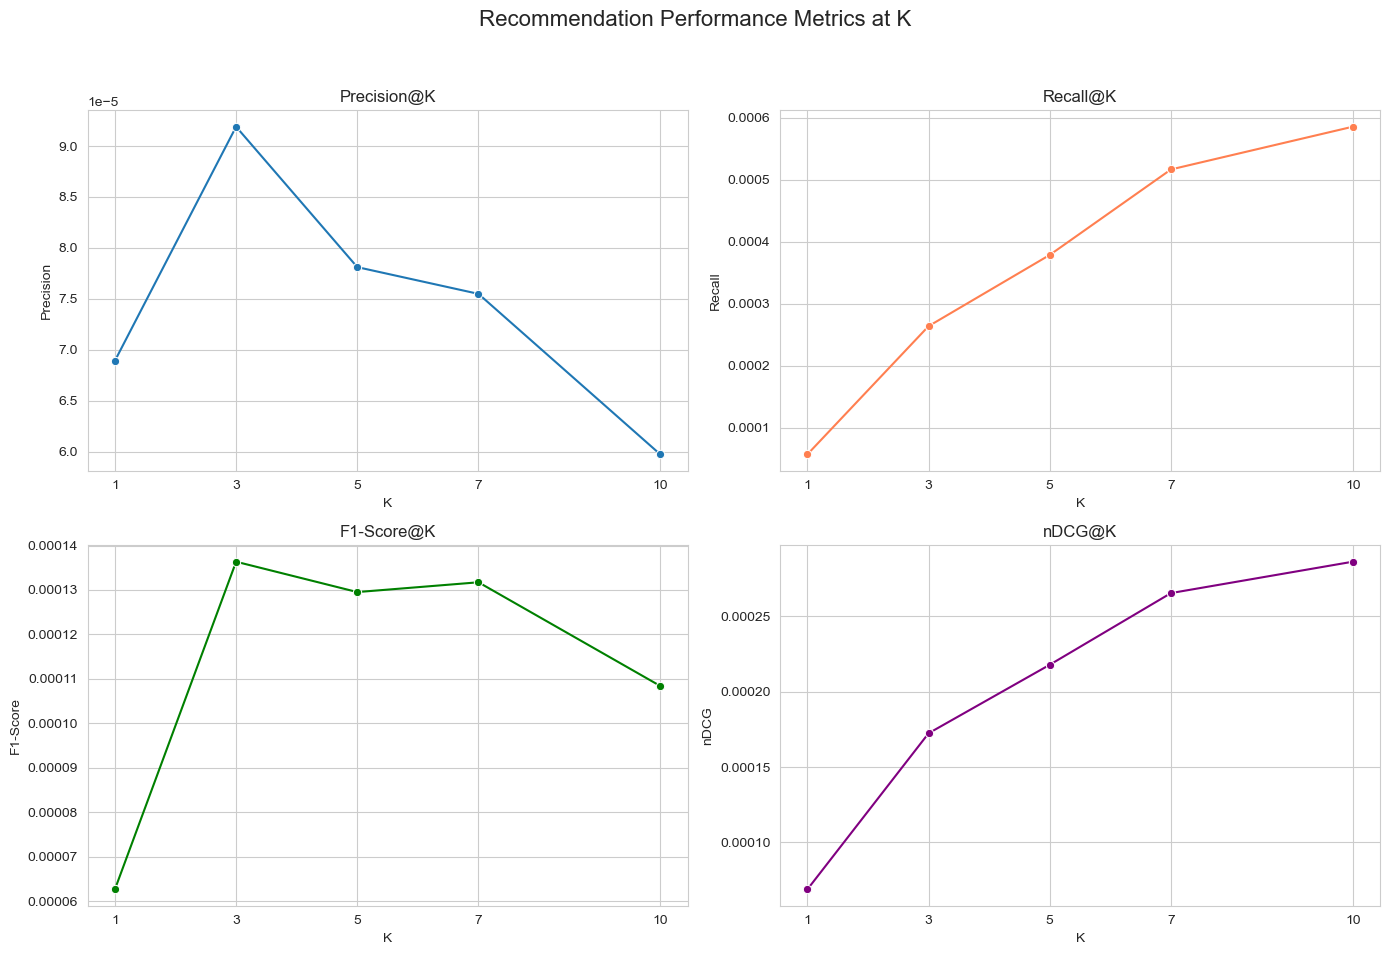


Metrics Table:
 K  Precision   Recall  F1-Score     nDCG
 1   0.000069 0.000057  0.000063 0.000069
 3   0.000092 0.000264  0.000136 0.000172
 5   0.000078 0.000379  0.000130 0.000218
 7   0.000075 0.000517  0.000132 0.000265
10   0.000060 0.000586  0.000108 0.000286


In [8]:
# Evaluate nDCG at k
def dcg_at_k(relevance, k):
    """Calculate Discounted Cumulative Gain."""
    relevance = np.asfarray(relevance)[:k]
    if relevance.size:
        # Use a vectorized log calculation for speed
        discounts = np.log2(np.arange(2, relevance.size + 2))
        return np.sum(relevance / discounts)
    return 0.

def ndcg_at_k(relevance, k):
    """Calculate Normalized Discounted Cumulative Gain."""
    dcg = dcg_at_k(relevance, k)
    # Sort true relevance scores to get the ideal ranking
    ideal_relevance = sorted(relevance, reverse=True)
    idcg = dcg_at_k(ideal_relevance, k)
    if not idcg:
        return 0.
    return dcg / idcg

print("\n--- Comprehensive Evaluation for K=1 to 10 ---")
K_RANGE = [1,3,5,7,10]
relevance_threshold = 3.0

# Lists to store the average scores for each K
avg_precisions = []
avg_recalls = []
avg_f1s = []
avg_ndcgs = []

# Prepare data for evaluation
test_csr = test_weights.tocsr()
train_csr = train_interactions.tocsr()
n_users, n_items = test_csr.shape
item_ids = np.arange(n_items)

# This list will store per-user metric lists
user_results = []

for user_id in tqdm(range(n_users), desc="Evaluating Users"):
    # Get true data for the user
    true_ratings = test_csr[user_id].toarray().flatten()
    relevant_items = np.where(true_ratings >= relevance_threshold)[0]
    
    # Skip users with no relevant items in the test set
    if len(relevant_items) == 0:
        continue
    
    # Get predictions
    train_positives = train_csr[user_id].indices
    predictions = model.predict(user_id, item_ids, item_features=item_features_matrix)
    predictions[train_positives] = -np.inf
    predicted_rank_indices = np.argsort(-predictions)
    
    # Get relevance scores in ranked order for nDCG
    ranked_relevance = true_ratings[predicted_rank_indices]
    
    # Calculate metrics for each K for this user
    user_precisions = []
    user_recalls = []
    user_ndcgs = []
    
    for k in K_RANGE:
        top_k_items = predicted_rank_indices[:k]
        
        # Precision and Recall
        hits = np.intersect1d(top_k_items, relevant_items).shape[0]
        precision = hits / k
        recall = hits / len(relevant_items)
        
        user_precisions.append(precision)
        user_recalls.append(recall)
        
        # nDCG
        user_ndcgs.append(ndcg_at_k(ranked_relevance, k))
        
    user_results.append({
        'precision': user_precisions,
        'recall': user_recalls,
        'ndcg': user_ndcgs
    })

# Average the metrics across all users
for k_idx, k in enumerate(K_RANGE):
    avg_precisions.append(np.mean([res['precision'][k_idx] for res in user_results]))
    avg_recalls.append(np.mean([res['recall'][k_idx] for res in user_results]))
    avg_ndcgs.append(np.mean([res['ndcg'][k_idx] for res in user_results]))

# Calculate F1 score from the averaged precision and recall
for p, r in zip(avg_precisions, avg_recalls):
    if p + r > 0:
        avg_f1s.append(2 * (p * r) / (p + r))
    else:
        avg_f1s.append(0.0)

# --- 6. Visualization of Results ---

print("\n--- Evaluation Results Visualization ---")
results_df = pd.DataFrame({
    'K': list(K_RANGE),
    'Precision': avg_precisions,
    'Recall': avg_recalls,
    'F1-Score': avg_f1s,
    'nDCG': avg_ndcgs
})

sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Recommendation Performance Metrics at K', fontsize=16)

# Plot Precision
sns.lineplot(ax=axes[0, 0], x='K', y='Precision', data=results_df, marker='o')
axes[0, 0].set_title('Precision@K')
axes[0, 0].set_xticks(K_RANGE)

# Plot Recall
sns.lineplot(ax=axes[0, 1], x='K', y='Recall', data=results_df, marker='o', color='coral')
axes[0, 1].set_title('Recall@K')
axes[0, 1].set_xticks(K_RANGE)

# Plot F1-Score
sns.lineplot(ax=axes[1, 0], x='K', y='F1-Score', data=results_df, marker='o', color='green')
axes[1, 0].set_title('F1-Score@K')
axes[1, 0].set_xticks(K_RANGE)

# Plot nDCG
sns.lineplot(ax=axes[1, 1], x='K', y='nDCG', data=results_df, marker='o', color='purple')
axes[1, 1].set_title('nDCG@K')
axes[1, 1].set_xticks(K_RANGE)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

print("\nMetrics Table:")
print(results_df.to_string(index=False))

In [11]:
# --- 6. (Optional but Recommended) Hyperparameter Tuning with Optuna ---
# To run this, you would need to `pip install optuna`
# This code provides a template for finding the best parameters.

import optuna

def objective(trial):
    # Define the search space for hyperparameters
    no_components = trial.suggest_int('no_components', 10, 50)
    learning_rate = trial.suggest_float('learning_rate', 1e-3, 5e-1, log=True)
    item_alpha = trial.suggest_float('item_alpha', 1e-4, 1e-2, log=True)
    user_alpha = trial.suggest_float('user_alpha', 1e-4, 1e-2, log=True)

    model = LightFM(loss='warp',
                    random_state=42,
                    no_components=no_components,
                    learning_rate=learning_rate,
                    item_alpha=item_alpha,
                    user_alpha=user_alpha)

    model.fit(train_interactions,
              sample_weight=train_weights,
              item_features=item_features_matrix,
              epochs=10, # Use fewer epochs during tuning for speed
              num_threads=4,
              verbose=False)

    # Evaluate on the test set
    test_auc = auc_score(model, test_interactions, train_interactions=train_interactions, item_features=item_features_matrix, num_threads=1).mean()

    return test_auc

print("\nStarting hyperparameter optimization with Optuna...")
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50) # Run 50 trials

print("\nBest trial:")
trial = study.best_trial
print(f"  AUC: {trial.value:.4f}")
print("  Best Parameters: ")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

[I 2025-11-10 08:52:01,372] A new study created in memory with name: no-name-98b72d2f-dde9-4081-ba96-bdd9dbb97a33



Starting hyperparameter optimization with Optuna...


[I 2025-11-10 08:55:12,913] Trial 0 finished with value: 0.5974321365356445 and parameters: {'no_components': 18, 'learning_rate': 0.001607381952787404, 'item_alpha': 0.0011263014595198522, 'user_alpha': 0.0003312948180779356}. Best is trial 0 with value: 0.5974321365356445.
[I 2025-11-10 09:01:02,528] Trial 1 finished with value: 0.6173252463340759 and parameters: {'no_components': 45, 'learning_rate': 0.018500709022167647, 'item_alpha': 0.0021752709000073564, 'user_alpha': 0.00033935145927103266}. Best is trial 1 with value: 0.6173252463340759.
[I 2025-11-10 09:04:31,857] Trial 2 finished with value: 0.5977905988693237 and parameters: {'no_components': 21, 'learning_rate': 0.0031314519204181804, 'item_alpha': 0.00032052341054594877, 'user_alpha': 0.0013150881362454252}. Best is trial 1 with value: 0.6173252463340759.
[I 2025-11-10 09:08:28,916] Trial 3 finished with value: 0.6223924160003662 and parameters: {'no_components': 24, 'learning_rate': 0.03924221705874015, 'item_alpha': 0.0


Best trial:
  AUC: 0.6626
  Best Parameters: 
    no_components: 50
    learning_rate: 0.44336493622612433
    item_alpha: 0.00010441070855357459
    user_alpha: 0.00010629909286349984
